# 02 · Reference photon labels from G-LiHT, and how often the ATL08 v007 photon classes are wrong

**Question:** inside G-LiHT airborne lidar strips in interior Alaska and on the Kenai, which ATL03 v007 photons are really
ground, canopy or noise, and how often do the **ATL08 v007 photon classes** get them wrong, by canopy height? This sets the
targets for the reclassifier (notebook 03) and provides the labelled photons that notebooks 03–06 evaluate against.

**The chain of steps** (per validation tile from notebook 00; one section each below):

| Step | Input | What happens | Output (in `work_dir/glihit/tile_<n>/`) |
|---|---|---|---|
| 1 | tile, G-LiHT strip list | Pick the tile's G-LiHT strips (ALS year) and download CHM + DTM (1 m) | `strips.csv`, files in `glihit_raw/` |
| 2 | CHM, DTM | **Reference surfaces**: ground and canopy top over each 11 m ICESat-2 footprint | files in `glihit_fp/` |
| 3 | strip areas, ATL03 v007 granules | Download **ATL03 v007 photons** with **ATL08 v007 photon classes**; also the **current v7 30 m (ATL08 classes → PhoREAL)** segments | `photons_atl03.parquet`, `phoreal.parquet` |
| 4 | photons (ATL08 ground), DTM | **Align** each track to the G-LiHT ground (shift + vertical offset) | `offsets.csv` |
| 5 | photons, reference surfaces | **Reference photon labels** (ground / canopy / noise; the truth) | column `ref_label` |
| 6 | photons | **Disturbance screen**: Hansen forest loss in or after the ALS year → flagged, excluded from validation | column `disturbed`; `photons.parquet` |

ICESat-2 years: the growing seasons closest to the ALS flight (2019–2020 for 2018 flights; 2019 for 2014 flights).

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes (v0.1)** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds in `config/atl03_reclass_v0.1.yaml`. |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments (ATL08-style along-track segments), three versions from the same photons**
| Term | Photon classes used | 30 m binning | Role |
|---|---|---|---|
| **current v7 30 m (ATL08 classes → PhoREAL)** | ATL08 v007 | SlideRule PhoREAL (as in `process_atl08_boreal.py`) | What our training files contain today |
| **ATL08 classes → our 30 m (check)** | ATL08 v007 | ours (`segment_metrics`) | Check: separates the effect of our binning from our classification |
| **reclassified photons → our 30 m (new)** | reclassified v0.1 | ours (`segment_metrics`) | The new product being tested |

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.1.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)
FIG = WORK / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.1 d49984a76293 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7d697cc",
 "git_dirty_lib_or_config": true,
 "config_version": "0.1",
 "config_sha1": "d49984a76293",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T05:02:57"
}


In [2]:
INV = WORK / "inventory"; GL = WORK / "glihit"; GL.mkdir(exist_ok=True)
selected = gpd.read_parquet(INV / "selected_tiles.parquet")
strips_all = gpd.read_parquet(INV / "glihit_strips_alaska.parquet")
MAX_STRIPS_PER_TILE = 60          # largest strips first; keeps a tile to a few hundred SlideRule requests
YEARS_FOR_ALS = {2018: [2019, 2020], 2014: [2019]}
sliderule = ipl.sliderule_init()
TILES = {int(r.tile_num): r for r in selected.itertuples()}
selected.drop(columns="geometry")

,tile_num,tile_version,tile_group,map_version,region,glihit_year,glihit_km2_2014,glihit_km2_2018
0,3457,version 1,north america west,NaN,Interior,2018,8887.774315,446.237549
1,3553,version 1,north america west,NaN,Interior,2018,3244.173814,391.952350
2,3836,version 1,north america west,NaN,Kenai,2018,0.000000,806.438841
3,3928,version 1,north america west,NaN,Kenai,2018,389.328692,785.492737


## Step 1 · G-LiHT strips for each tile

**Input:** the tile polygon and the G-LiHT strip footprints found in notebook 00.

**What happens:** keep the strips flown in the tile's ALS year (2018 here), largest first (up to 60), and download each strip's
1 m canopy height model (`GLCHMT`) and terrain model (`GLDTMT`) from LP DAAC with your Earthdata login
(`lib: download, earthdata_login`; files already downloaded are skipped).

**Output:** `strips.csv` per tile (strip name, local CHM and DTM paths).

In [3]:
strips = {}
for t, r in TILES.items():
    tdir = GL / f"tile_{t}"; tdir.mkdir(exist_ok=True)
    s = strips_all[(strips_all.year == r.glihit_year) & strips_all.intersects(r.geometry)].copy()
    s["area"] = s.to_crs(3338).area
    s = s.sort_values("area", ascending=False).head(MAX_STRIPS_PER_TILE)
    s["chm"] = ref.download(s.https_chm.tolist(), WORK / "glihit_raw", cfg["paths"].get("credentials_ini"))
    s["dtm"] = ref.download(s.https_dtm.tolist(), WORK / "glihit_raw", cfg["paths"].get("credentials_ini"))
    strips[t] = s
pd.DataFrame({t: {"region": TILES[t].region, "ALS year": TILES[t].glihit_year, "strips": len(s),
                  "strip area (km2)": round(s.area.sum() / 1e6)} for t, s in strips.items()}).T

/explore/nobackup/people/pmontesa/envs/atl03reclass/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_2702332/3735078563.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  "strip area (km2)": round(s.area.sum() / 1e6)} for t, s in strips.items()}).T
/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_2702332/3735078563.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  "strip area (km2)": round(s.area.sum() / 1e6)} for t, s in strips.items()}).T
/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_2702332/3735078563.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  "strip area (km2)": round(s.area.sum() / 1e6)} for t, s in

,region,ALS year,strips,strip area (km2)
3457,Interior,2018,54,0
3553,Interior,2018,60,0
3836,Kenai,2018,60,0
3928,Kenai,2018,60,0


## Step 2 · Reference surfaces over the ICESat-2 footprint

**Input:** each strip's 1 m CHM and DTM.

**What happens:** for every 1 m cell, the mean DTM within an 11 m circle (the footprint) = **reference ground**, and that
ground + the highest CHM value within the circle = **reference canopy top**. The DTM is warped onto the CHM grid first.
(`lib: footprint_surfaces`)

**Output:** `<strip>_dtmfp.tif` and `<strip>_topfp.tif` in `glihit_fp/`.

In [4]:
for t, s in strips.items():
    fps = [ref.footprint_surfaces(c, d, WORK / "glihit_fp", cfg["reference_labels"]["footprint_diameter_m"]) for c, d in zip(s.chm, s.dtm)]
    s["dtmfp"], s["topfp"] = [f[0] for f in fps], [f[1] for f in fps]
    s.drop(columns="geometry").to_csv(GL / f"tile_{t}" / "strips.csv", index=False)
print({t: len(s) for t, s in strips.items()}, "strips with reference surfaces")

{3457: 54, 3553: 60, 3836: 60, 3928: 60} strips with reference surfaces


## Step 3 · ATL03 v007 photons with their ATL08 v007 photon classes, and the current v7 30 m segments

**Input:** each strip's area (plus ~200 m) and the ATL03 v007 granules over it in the ICESat-2 years for that ALS year.

**What happens:** SlideRule returns **every photon** (signal and background) with its **ATL08 v007 photon class**
(`lib: fetch_photons`), and separately the **current v7 30 m (ATL08 classes → PhoREAL)** segments over the same area
(`lib: fetch_phoreal`). Photons in overlapping strips are kept once.

**Output:** `photons_atl03.parquet` (one row per photon) and `phoreal.parquet` (one row per current v7 30 m segment).

In [5]:
photons = {}
for t, s in strips.items():
    tdir = GL / f"tile_{t}"
    fn, fn_old = tdir / "photons_atl03.parquet", tdir / "photons.parquet"
    if fn.exists():
        photons[t] = gpd.read_parquet(fn); continue
    if fn_old.exists():                        # from an earlier run: keep the raw photon columns only
        g = gpd.read_parquet(fn_old)
        photons[t] = g.drop(columns=[c for c in ["ref_ground", "ref_top", "ref_label", "ref_relief", "hansen_lossyear", "disturbed"] if c in g])
        continue
    ph_all, pr_all = [], []
    for st in s.itertuples():
        grs = ipl.granules_from_cmr(st.geometry, YEARS_FOR_ALS[TILES[t].glihit_year], cfg["icesat2"]["months"], release=cfg["icesat2"]["release"])
        if not grs: continue
        aoi = st.geometry.buffer(0.002)
        ph = ipl.fetch_photons(aoi, grs, cfg)
        if len(ph): ph_all.append(ph.assign(strip=st.stem))
        pr = ipl.fetch_phoreal(aoi, grs, cfg)
        if len(pr): pr_all.append(pr.assign(strip=st.stem))
    if not ph_all:
        print(t, "no photons"); continue
    ph = gpd.GeoDataFrame(pd.concat(ph_all, ignore_index=True), crs=ph_all[0].crs).drop_duplicates(subset=["track_id", "ph_index"])
    ph = ph.assign(tile_num=t, region=TILES[t].region, als_year=TILES[t].glihit_year)
    ipl.write_parquet(ph, fn, ipl.provenance(cfg, tile_num=t, strips=s.stem.tolist()))
    if pr_all:
        pr = gpd.GeoDataFrame(pd.concat(pr_all, ignore_index=True), crs=pr_all[0].crs).drop_duplicates(subset=["track_id", "x_atc"])
        ipl.write_parquet(pr, tdir / "phoreal.parquet", ipl.provenance(cfg, tile_num=t))
    photons[t] = ph
pd.DataFrame({t: {"photons": len(p), "tracks": p.track_id.nunique(), "daytime share": round((p.solar_elevation > 0).mean(), 2)}
              for t, p in photons.items()}).T

,photons,tracks,daytime share
3457,2687449.0,62.0,0.94
3553,7673896.0,136.0,0.99
3836,6188192.0,129.0,0.97
3928,2452477.0,128.0,0.96


## Step 4 · Align each ICESat-2 track to the G-LiHT ground

**Input:** photons ATL08 labelled ground, and the 1 m G-LiHT DTMs.

**What happens:** per track, the horizontal shift (±6 m, 2 m steps) and vertical offset that best line up those ground photons
with the DTM. The vertical offset is mostly the ellipsoid–geoid separation (ICESat-2 heights are ellipsoidal; G-LiHT DTMs are
orthometric) and should be nearly constant within a tile. `mad` = remaining spread of ground photons around the DTM (m).
(`lib: track_offsets`)

**Output:** `offsets.csv` per tile.

,dx,dy,dz,mad,n
tile,,,,,
3457,0.0,0.0,11.52,0.12,185.0
3553,0.0,0.0,16.48,0.15,244.0
3836,0.0,2.0,11.45,0.24,134.0
3928,-2.0,2.0,2.19,0.09,171.0


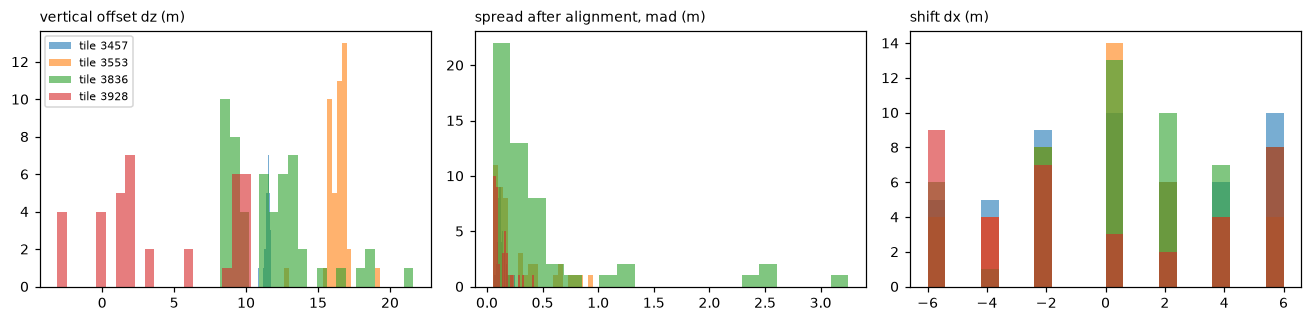

In [6]:
offsets = {}
for t, ph in photons.items():
    offsets[t] = ref.track_offsets(ph, strips[t].dtm.tolist(), cfg)
    offsets[t].to_csv(GL / f"tile_{t}" / "offsets.csv", index=False)
offs = pd.concat([o.assign(tile=t) for t, o in offsets.items()], ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, c, lab in zip(axes, ["dz", "mad", "dx"], ["vertical offset dz (m)", "spread after alignment, mad (m)", "shift dx (m)"]):
    for t, g in offs.groupby("tile"):
        ax.hist(g[c], bins=20, alpha=0.6, label=f"tile {t}")
    ax.set_title(lab, loc="left", fontsize=9)
axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "02_offsets.png", dpi=150)
offs.groupby("tile")[["dx", "dy", "dz", "mad", "n"]].median().round(2)

## Step 5 · Reference photon labels (the truth)

**Input:** photons, the footprint ground and canopy-top surfaces (step 2), the offsets (step 4).

**What happens:** as in notebook 01 (after Purslow et al. 2023, Fig. 1): within ±0.5 m of the reference ground → **ground**;
above that up to 1 m over the reference canopy top → **canopy**; more than 5 m beyond those windows → **noise**; in between →
**buffer** (excluded); outside G-LiHT → **none**. (`lib: label_photons`)

**Output:** columns `ref_label`, `ref_ground`, `ref_top`, `ref_relief`.

In [7]:
for t in photons:
    photons[t] = ref.label_photons(photons[t], strips[t].dtmfp.tolist(), strips[t].topfp.tolist(), offsets[t], cfg)
pd.DataFrame({t: p.ref_label.value_counts() for t, p in photons.items()}).fillna(0).astype(int).T

ref_label,buffer,canopy,ground,noise,none
3457,3090,9340,60101,53495,2561423
3553,5903,3912,20071,194755,7449255
3836,10979,18539,15478,281636,5861560
3928,2374,5838,13167,58574,2372524


## Step 6 · Disturbance screen

**Input:** photon positions, the ALS year.

**What happens:** Hansen Global Forest Change loss year is read at each photon; photons where forest was lost **in or after**
the G-LiHT flight year are flagged `disturbed` (the 2019 Swan Lake fire burned inside the Kenai flight area). They are kept
in the files but excluded from all validation. (`lib: hansen_lossyear`)

**Output:** columns `hansen_lossyear`, `disturbed`; the labelled photons saved as `photons.parquet`.

In [8]:
for t, ph in photons.items():
    loss = ref.hansen_lossyear(ph.lon, ph.lat, cfg["validation"]["disturbance"]["hansen_version"])
    ph["hansen_lossyear"] = loss
    ph["disturbed"] = (loss > 0) & (loss + 2000 >= TILES[t].glihit_year)
    ipl.write_parquet(ph, GL / f"tile_{t}" / "photons.parquet",
                      ipl.provenance(cfg, tile_num=t, strips=strips[t].stem.tolist(), als_year=int(TILES[t].glihit_year)))
    print(f"tile {t} ({TILES[t].region}): {len(ph):,} photons, {ph.track_id.nunique()} tracks, "
          f"{(ph.ref_label != 'none').mean():.0%} inside G-LiHT, {ph.disturbed.mean():.1%} disturbed")

tile 3457 (Interior): 2,687,449 photons, 62 tracks, 5% inside G-LiHT, 0.7% disturbed


tile 3553 (Interior): 7,673,896 photons, 136 tracks, 3% inside G-LiHT, 0.0% disturbed


tile 3836 (Kenai): 6,188,192 photons, 129 tracks, 5% inside G-LiHT, 0.2% disturbed


tile 3928 (Kenai): 2,452,477 photons, 128 tracks, 3% inside G-LiHT, 0.0% disturbed


# Results

## A · Photons along example tracks: short, medium and tall forest

One track per canopy-height regime (median reference canopy height < 5 m, 5–15 m, > 15 m), first 400 m inside G-LiHT.
Top row: the **ATL08 v007 photon classes**, with the reference ground (solid) and reference canopy top (dashed). Bottom row:
the **reference photon labels** for the same photons.

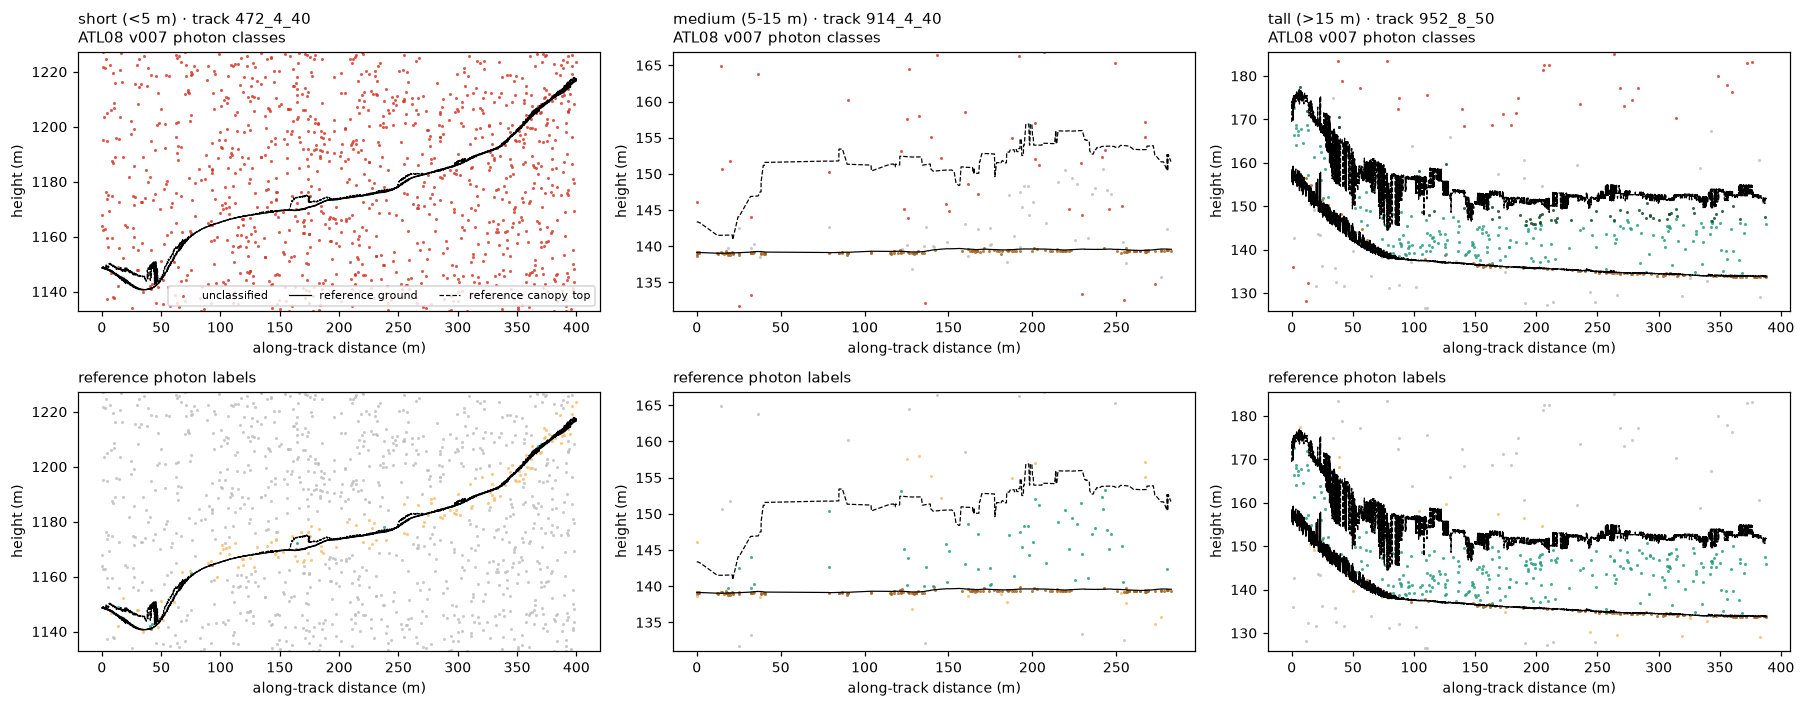

In [9]:
ph = pd.concat(photons.values(), ignore_index=True)
ph = ph[(ph.ref_label != "none") & ~ph.disturbed]
ph["ref_ch"] = ph["ref_top"] - ph["ref_ground"]
trk = ph.groupby("track_id").agg(n=("ref_ch", "size"), ch=("ref_ch", "median"), region=("region", "first"))
trk = trk[trk.n > 300]
picks = {}
for lab, lo, hi in [("short (<5 m)", 0, 5), ("medium (5-15 m)", 5, 15), ("tall (>15 m)", 15, 99)]:
    t = trk[(trk.ch >= lo) & (trk.ch < hi)]
    if len(t): picks[lab] = t.n.idxmax()
fig, axes = plt.subplots(2, len(picks), figsize=(5.5 * len(picks), 6.5), squeeze=False)
for j, (lab, tid) in enumerate(picks.items()):
    p = ph[ph.track_id == tid].sort_values("x_atc")
    p = p[p.x_atc < p.x_atc.min() + 400]
    p = p.assign(ref_code=p.ref_label.map({"noise": 0, "ground": 1, "canopy": 2, "buffer": 5}))
    val.plot_profile(axes[0, j], p, "atl08_class", val.ATL08_NAMES, title=f"{lab} · track {tid}\n{val.PHOTON_ATL08}")
    val.plot_profile(axes[1, j], p, "ref_code", {0: "noise", 1: "ground", 2: "canopy", 5: "buffer"}, title=val.PHOTON_REF)
    lo, hi = np.nanpercentile(p.ref_ground, 1) - 8, np.nanpercentile(p.ref_top, 99) + 10
    for a in axes[:, j]: a.set_ylim(lo, hi)
axes[0, 0].legend(fontsize=7, ncol=3)
fig.tight_layout(); fig.savefig(FIG / "02_profiles_by_height.png", dpi=150)

## B · How often the ATL08 v007 photon classes are wrong, by canopy height

Rows: **reference photon label**; columns: **ATL08 v007 photon class**; one panel per reference canopy-height class;
row-normalised. Three error rates in the table:
- **ground_as_canopy**: reference-ground photons labelled canopy → spurious height over short vegetation
- **canopy_as_noise_or_unclass**: reference-canopy photons dropped → underestimated tall canopy
- **noise_as_canopy**: background photons labelled canopy → spurious height anywhere

,reference canopy height,photons,ground_as_canopy,canopy_as_noise_or_unclass,noise_as_canopy
0,0-2 m,404996,0.030,0.252,0.004
1,2-5 m,73347,0.071,0.105,0.003
2,5-10 m,93976,0.105,0.107,0.002
3,10-15 m,63360,0.120,0.115,0.001
4,15-20 m,61416,0.173,0.142,0.000
5,20+ m,32722,0.160,0.234,0.000


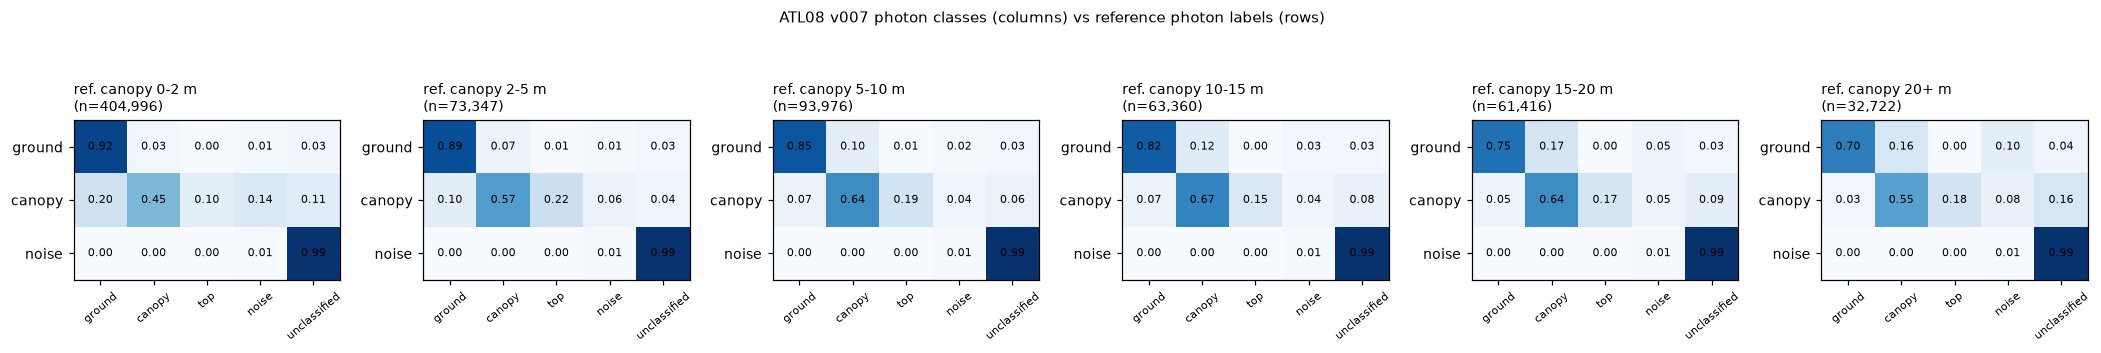

In [10]:
edges = [0, 2, 5, 10, 15, 20, 60]
ph["ch_class"] = pd.cut(ph.ref_ch, edges, right=False, labels=val.height_class_labels(edges))
lab = ph[ph.ref_label.isin(["ground", "canopy", "noise"])]
cls = list(lab.ch_class.cat.categories)
fig, axes = plt.subplots(1, len(cls), figsize=(3.2 * len(cls), 3.3))
rows = []
for ax, c in zip(axes, cls):
    sub = lab[lab.ch_class == c]
    if not len(sub): ax.axis("off"); continue
    t, tn = val.confusion(sub.ref_label, sub.atl08_class, val.ATL08_NAMES)
    tn = tn.reindex(index=["ground", "canopy", "noise"], columns=["ground", "canopy", "top", "noise", "unclassified"]).fillna(0)
    ax.imshow(tn.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(tn.shape[1]), tn.columns, rotation=40, fontsize=7); ax.set_yticks(range(3), tn.index)
    for i in range(3):
        for k in range(tn.shape[1]):
            ax.text(k, i, f"{tn.iat[i, k]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"ref. canopy {c}\n(n={len(sub):,})", fontsize=9, loc="left")
    rows.append({"reference canopy height": c, "photons": len(sub),
                 "ground_as_canopy": tn.loc["ground", ["canopy", "top"]].sum(),
                 "canopy_as_noise_or_unclass": tn.loc["canopy", ["noise", "unclassified"]].sum(),
                 "noise_as_canopy": tn.loc["noise", ["canopy", "top"]].sum()})
fig.suptitle(f"{val.PHOTON_ATL08} (columns) vs {val.PHOTON_REF} (rows)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "02_confusion_atl08_by_height.png", dpi=150)
pd.DataFrame(rows).round(3)

## Results
To be summarised after review: the ATL08 v007 error rates by height class (table B) are the targets for notebook 03.